# AML Transaction Monitoring

Rules to catch structuring, money mules and dormant account abuse, a model to triage the alerts they raise, and an anomaly model to find what the rules miss. Everything is measured on alert quality: how many alerts, how many are real, and how many real cases slip through.

The data is simulated (see `src/simulate.py`) because no bank publishes labelled laundering data. The upside is that every planted case has a known answer, so precision and recall can be measured exactly.

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.simulate import simulate, CASH_THRESHOLD
from src.features import daily, rolling_window, customer_features
from src import rules
from src.model import anomaly_scores, triage_scores, feature_importance
from src.evaluate import (rule_quality, overall_quality, average_precision,
                          capacity_curve, precision_at_k)

pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 90)
FIG = "../reports/figures/"
BLUE, ORANGE, GREY = "#1f4e79", "#c55a11", "#9e9e9e"

def style(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(alpha=0.25)

## 1. The Data

5 000 customers over 120 days. 2% carry a planted typology. Stokvels, cash heavy small businesses and quiet accounts with lump sums are innocent but built to look suspicious.

In [2]:
customers, tx = simulate()
print(f"{len(tx):,} transactions")
pd.crosstab(customers["segment"], customers["typology"], margins=True)

339,384 transactions


typology,dormant,mule,none,structuring,All
segment,,,,,
low_activity,0,0,183,0,183
salaried,21,40,3862,19,3942
small_business,0,0,710,20,730
stokvel,0,0,145,0,145
All,21,40,4900,39,5000


In [3]:
tx.groupby(["channel", "direction"])["amount"].agg(["count", "median", "max"]).round(0)

count   median       max
channel direction                           
atm     out           372   7958.0   14506.0
card    out        205729    383.0   22035.0
cash    in          32812   9709.0  102219.0
eft     in          16299  17909.0  394869.0
        out         42877   3589.0  177112.0
instant in          40658    372.0   14996.0
        out           637  11273.0   55282.0

## 2. Rules

| Rule | Typology | Logic |
| --- | --- | --- |
| Structuring | cash smurfing | 3 or more cash deposits between 80% and 100% of the R49 999.99 threshold within 7 days |
| Pass through | money mule | 8 or more distinct senders in 7 days, R20 000 or more in, and 80% or more already sent out |
| Dormant reactivation | account takeover or rented account | 60 or more days with no activity, then R50 000 or more in within 7 days |

In [4]:
win = rolling_window(daily(tx))
alerts = rules.run_all(tx, win)
alerts = alerts.merge(customers[["customer_id", "segment", "typology"]], on="customer_id")
rule_quality(alerts, customers).round(3)

,rule,alerts,true_positives,false_positives,precision,recall_on_target
0,structuring,64,39,25,0.609,1.00
1,pass_through,124,32,92,0.258,0.75
2,dormant_reactivation,23,21,2,0.913,1.00


In [5]:
pd.Series(overall_quality(alerts["customer_id"], customers)).round(3)

customers_alerted            208.000
true_positives                90.000
precision                      0.433
recall                         0.900
alerts_per_1000_customers     41.600
dtype: float64

Every alert carries a reason an investigator can read without opening the account:

In [6]:
alerts.groupby("rule").head(2)[["customer_id", "rule", "alert_date", "reason", "typology"]]

,customer_id,rule,alert_date,reason,typology
0,C00072,structuring,2026-01-30,"3 cash deposits under the threshold in 7 days, R131,885 in total",none
1,C00075,structuring,2026-04-18,"3 cash deposits under the threshold in 7 days, R136,148 in total",none
64,C00076,pass_through,2026-01-09,"20 senders in 7 days, R30,000 in and 98% sent out",none
65,C00130,pass_through,2026-01-05,"10 senders in 7 days, R20,000 in and 103% sent out",none
188,C01731,dormant_reactivation,2026-03-12,"inactive 64 days, then R105,055 in within 7 days",none
189,C04800,dormant_reactivation,2026-04-13,"inactive 77 days, then R80,926 in within 7 days",none


Where do the false positives come from?

In [7]:
fp = alerts[alerts["typology"] == "none"]
fp_table = pd.crosstab(fp["rule"], fp["segment"])
fp_table

segment,low_activity,small_business,stokvel
rule,,,
dormant_reactivation,2,0,0
pass_through,0,15,77
structuring,0,25,0


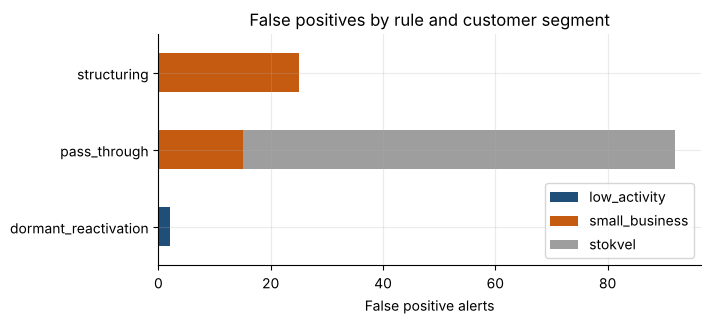

In [8]:
ax = fp_table.plot.barh(stacked=True, figsize=(7, 3), color=[BLUE, ORANGE, GREY, "#5b9bd5"][: fp_table.shape[1]])
ax.set(xlabel="False positive alerts", ylabel="", title="False positives by rule and customer segment")
ax.legend(title="", loc="lower right")
style(ax)
ax.figure.savefig(FIG + "false_positives.png", dpi=150, bbox_inches="tight")
plt.show()

Stokvels drive most of the pass through false positives: a treasurer collects from 8 to 30 members and pays out within days, which is exactly what a mule account does. Cash heavy small businesses drive the structuring false positives. Both are normal, legitimate South African banking behaviour, and a rule that cannot tell them apart from crime creates work for investigators and friction for customers.

## 3. Tuning

Each threshold trades alerts against missed cases. Below, the pass through rule at different minimum sender counts and the structuring rule at different floors.

In [9]:
rows = []
for n in [4, 6, 8, 10, 12, 15]:
    a = rules.pass_through(win, min_senders=n)
    q = rule_quality(a.assign(rule="pass_through"), customers).set_index("rule").loc["pass_through"]
    rows.append({"min_senders": n, "alerts": q["alerts"], "precision": q["precision"],
                 "recall": q["recall_on_target"]})
pt = pd.DataFrame(rows)
pt.round(3)

,min_senders,alerts,precision,recall
0,4,520.0,0.115,1.000
1,6,220.0,0.195,0.875
2,8,124.0,0.258,0.750
3,10,104.0,0.250,0.625
4,12,93.0,0.204,0.475
5,15,77.0,0.143,0.275


In [10]:
rows = []
for floor in [0.6, 0.7, 0.8, 0.9]:
    for n in [2, 3, 4]:
        a = rules.structuring(tx, min_count=n, floor=floor)
        q = rule_quality(a.assign(rule="structuring"), customers).set_index("rule").loc["structuring"]
        rows.append({"floor": floor, "min_count": n, "alerts": q["alerts"],
                     "precision": q["precision"], "recall": q["recall_on_target"]})
st = pd.DataFrame(rows)
st.round(3)

,floor,min_count,alerts,precision,recall
0,0.6,2,165.0,0.236,1.000
1,0.6,3,93.0,0.419,1.000
2,0.6,4,70.0,0.543,0.974
3,0.7,2,142.0,0.275,1.000
4,0.7,3,76.0,0.513,1.000
5,0.7,4,52.0,0.731,0.974
6,0.8,2,129.0,0.302,1.000
7,0.8,3,64.0,0.609,1.000
8,0.8,4,45.0,0.844,0.974
9,0.9,2,91.0,0.396,0.923


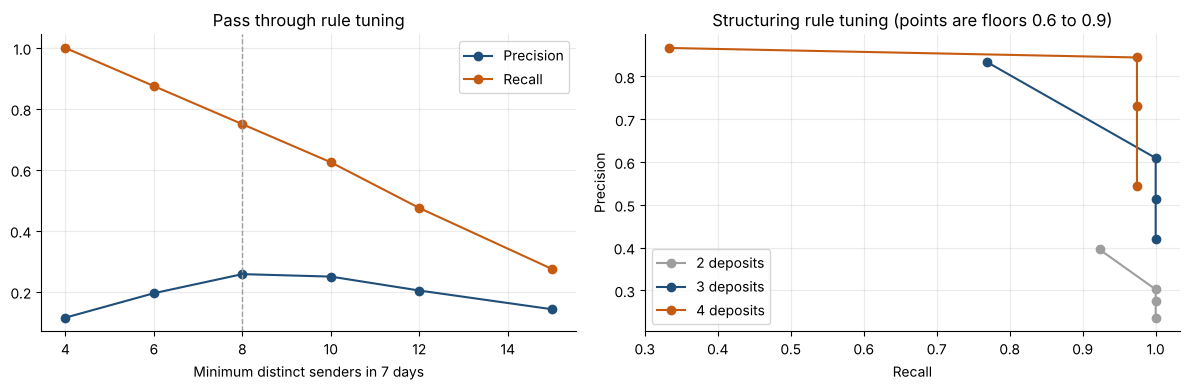

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(pt["min_senders"], pt["precision"], marker="o", color=BLUE, label="Precision")
ax[0].plot(pt["min_senders"], pt["recall"], marker="o", color=ORANGE, label="Recall")
ax[0].axvline(8, color=GREY, ls="--", lw=1)
ax[0].set(xlabel="Minimum distinct senders in 7 days", title="Pass through rule tuning")
ax[0].legend(); style(ax[0])
for n, c in zip([2, 3, 4], [GREY, BLUE, ORANGE]):
    s = st[st["min_count"] == n]
    ax[1].plot(s["recall"], s["precision"], marker="o", color=c, label=f"{n} deposits")
ax[1].set(xlabel="Recall", ylabel="Precision", title="Structuring rule tuning (points are floors 0.6 to 0.9)")
ax[1].legend(); style(ax[1])
plt.tight_layout()
fig.savefig(FIG + "tuning.png", dpi=150, bbox_inches="tight")
plt.show()

**Pass through.** Precision peaks at 8 to 10 senders. Above that, both precision and recall fall: large stokvels with 15 or more members still alert, while smaller mule rings drop out. Going down to 6 senders lifts recall from 75% to 88% but nearly doubles the alerts. The sender count alone cannot separate stokvels from mules, which is the argument for the triage model below.

**Structuring.** Moving from 3 to 4 deposits at the 80% floor raises precision from 61% to 84% and cuts alerts from 64 to 45, while recall only drops from 100% to 97%. That is the change I would put to a compliance committee, with a note that the one missed structurer is the cost.

In a real bank every threshold change is documented and signed off, and checked with below the line testing: sampling customers just under each threshold to see what the rule is missing.

## 4. Alert Triage Model

The rules raise alerts; a model trained on past investigation outcomes ranks them so investigators work the most likely cases first. Scores are out of fold (5 fold cross validation), so every alert is scored by a model that never saw it.

I also gave it two features built around what investigators check: whether senders pay repeatedly (stokvel members do, scam victims sending to a mule do not) and whether amounts are round.

In [12]:
alerted = alerts["customer_id"].unique()
feats = customer_features(tx, customers)
y_all = customers.set_index("customer_id")["is_suspicious"]
Xa, ya = feats.loc[alerted], y_all.loc[alerted]

triage = triage_scores(Xa, ya)
print(f"alerts: {len(ya)}, suspicious: {ya.sum()} ({ya.mean():.0%})")
print(f"average precision of triage ranking: {average_precision(ya, triage):.3f} (random ranking = {ya.mean():.3f})")
cap = capacity_curve(ya, triage, [20, 40, 60, 80, 100, 120, 160, len(ya)])
cap.round(3)

alerts: 208, suspicious: 90 (43%)
average precision of triage ranking: 0.990 (random ranking = 0.433)


,k,precision,recall
0,20,1.000,0.222
1,40,1.000,0.444
2,60,0.983,0.656
3,80,0.988,0.878
4,100,0.890,0.989
5,120,0.750,1.000
6,160,0.562,1.000
7,208,0.433,1.000


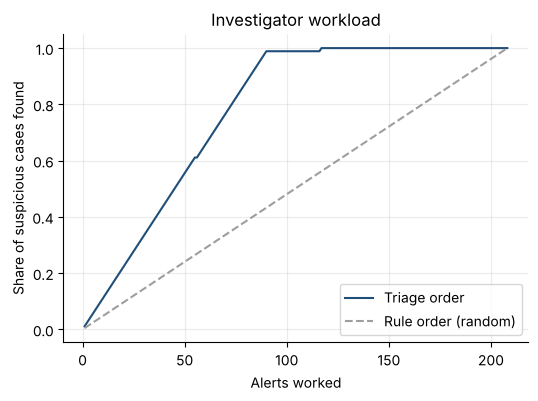

In [13]:
order = np.argsort(-triage.values)
found = np.cumsum(ya.values[order]) / ya.sum()
rand = np.arange(1, len(ya) + 1) / len(ya)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(np.arange(1, len(ya) + 1), found, color=BLUE, label="Triage order")
ax.plot(np.arange(1, len(ya) + 1), rand, color=GREY, ls="--", label="Rule order (random)")
ax.set(xlabel="Alerts worked", ylabel="Share of suspicious cases found", title="Investigator workload")
ax.legend(); style(ax)
fig.savefig(FIG + "triage_capacity.png", dpi=150, bbox_inches="tight")
plt.show()

In [14]:
feature_importance(Xa, ya).head(6).round(3)

n_in             0.633
total_out        0.339
total_in         0.016
avg_in_amount    0.012
cash_in_share    0.000
n_out            0.000
dtype: float64

In practice the model leans almost entirely on the number of inbound payments and total outflows. Stokvels and small businesses receive far more payments over 120 days than a mule does in its short active window, so the two hand built features were not needed here. On real data, where volumes overlap more, features like these matter more.

**Caveat.** On this data the triage model separates alerts almost perfectly. That is a property of simulated data: the planted cases differ from innocent customers more cleanly than real ones do, and real investigation labels are noisy. On real alerts, a good triage model typically lets a team close a large share of low scoring alerts with light review rather than eliminating them. The method and the evaluation are what carry over: out of fold scoring, ranking by capacity, and checking which features drive the score so it can be explained to a regulator.

## 5. Anomaly Model: What The Rules Miss

Rules only catch patterns someone wrote down. An isolation forest scores every customer on how unusual they are, with no labels. Used on its own it mostly flags innocent but unusual customers. Used as a second line, on customers the rules did not alert, it can surface missed cases.

In [15]:
anom = anomaly_scores(feats)
print(f"average precision on all customers: {average_precision(y_all.loc[anom.index], anom):.3f} (random = {y_all.mean():.3f})")

not_alerted = anom.drop(index=alerted)
missed = customers[(customers["is_suspicious"] == 1) & (~customers["customer_id"].isin(alerted))]
print(f"suspicious customers the rules missed: {len(missed)} ({missed['typology'].value_counts().to_dict()})")

rank = not_alerted.rank(ascending=False)
rows = []
for k in [25, 50, 100, 200]:
    top = rank[rank <= k].index
    rows.append({"review_top_k": k, "missed_cases_found": int(y_all.loc[top].sum()),
                 "share_of_missed": y_all.loc[top].sum() / len(missed)})
pd.DataFrame(rows).round(3)

average precision on all customers: 0.270 (random = 0.020)
suspicious customers the rules missed: 10 ({np.str_('mule'): 10})


,review_top_k,missed_cases_found,share_of_missed
0,25,0,0.0
1,50,2,0.2
2,100,4,0.4
3,200,10,1.0


In [16]:
top_unusual = not_alerted.sort_values(ascending=False).head(10).index
customers.set_index("customer_id").loc[top_unusual, ["segment", "typology"]].value_counts()

segment       typology
low_activity  none        10
Name: count, dtype: int64

The most unusual customers the rules did not alert are mostly innocent, which is why an anomaly score is a poor alert on its own. As a periodic second line review it still adds value: reviewing the 100 most unusual non alerted customers finds 4 of the 10 missed mules, and the top 200 finds all 10. Those finds would then feed back into the rules, for example a lower sender threshold for new accounts.

## 6. Summary

- Three rules catch most planted cases with a few dozen alerts per 1 000 customers.
- False positives come from stokvels and cash heavy small businesses, which are normal South African banking behaviour.
- Tuning shows the trade off explicitly, which is what a tuning memo to a compliance committee needs.
- A triage model ranks alerts by likelihood so investigator time goes to the right cases first.
- An anomaly model, used as a second line on non alerted customers, recovers part of what the rules miss.

The write up is in `reports/tuning_memo.md`.